In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import r2_score

# train guard 
sys.path.insert(0, str(Path("../scripts").resolve()))

# relevant functions and classes that will be used here
from train_cnn import EDGES, GROUPS, BrainAgeCNN, load_split, eval_windows, predict_children, mae_scores

CNN_RUN = Path("../outputs/cnn16s")
RIDGE_RUN = Path("../outputs/ridge")
FIG = Path("../outputs/figures")
FIG.mkdir(parents=True, exist_ok=True)
COLOR = {"ridge": "#2a78d6", "CNN": "#eb6834"}   # the same colour for a model in every figure

def evaluate(age, pred):
    # copied from cell 5 of 01_baseline, makes columns uniform
    err = np.abs(pred - age)
    group = pd.cut(age, EDGES, right=False, labels=GROUPS)
    per_group = pd.Series(err).groupby(group, observed=False).mean()
    return {"MAE": err.mean(), "balanced MAE": per_group.mean(), **per_group.to_dict(),
            "r": np.corrcoef(age, pred)[0, 1], "R2": r2_score(age, pred)}


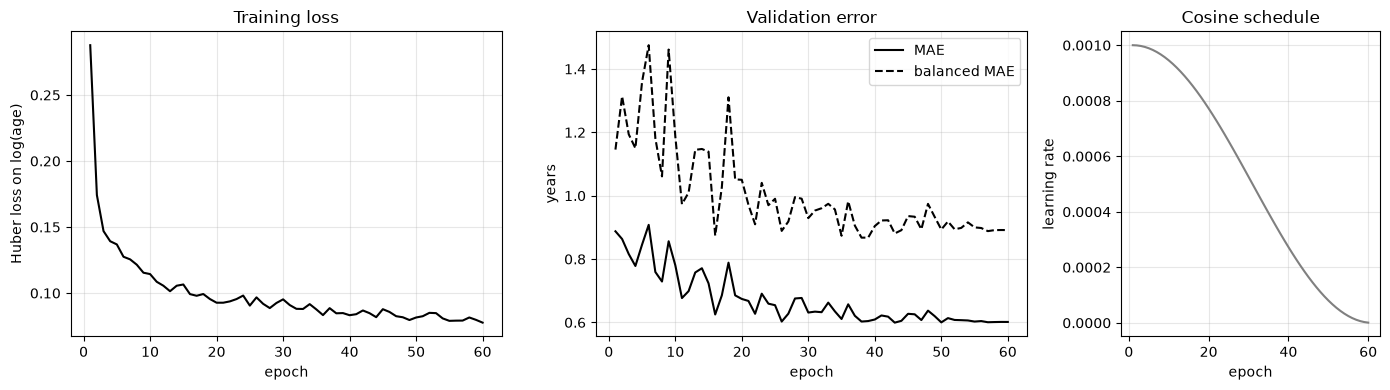

In [2]:
curve = pd.read_csv(CNN_RUN / "learning_curve.csv")

fig, (ax_loss, ax_mae, ax_lr) = plt.subplots(1, 3, figsize=(14, 4), width_ratios=[1, 1, 0.6])
ax_loss.plot(curve.epoch, curve.train_loss, color="black")
ax_loss.set(xlabel="epoch", ylabel="Huber loss on log(age)", title="Training loss")


# black lines here: blue and orange mean ridge and CNN in the other figures
ax_mae.plot(curve.epoch, curve.val_MAE, color="black", label="MAE")
ax_mae.plot(curve.epoch, curve.val_balanced_MAE, color="black", linestyle="--", label="balanced MAE")
ax_mae.set(xlabel="epoch", ylabel="years", title="Validation error")
ax_mae.legend()

# the learning rate gets its own small panel instead of a second y-axis on the val plot
ax_lr.plot(curve.epoch, curve.lr, color="grey")
ax_lr.set(xlabel="epoch", ylabel="learning rate", title="Cosine schedule")
for ax in (ax_loss, ax_mae, ax_lr):
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "cnn_learning_curve.png", dpi=150)
plt.show()


In [3]:
cnn = pd.read_csv(CNN_RUN / "val_predictions.csv")
ridge = pd.read_csv(RIDGE_RUN / "val_predictions.csv")
both = cnn.merge(ridge, on="id", suffixes=("_cnn", "_ridge"), validate="one_to_one")  # on id  always, never row order

assert len(both) == 103, f"{len(both)} children in both files, expected 103"
# CNN ages were saved as float32, ridge ages as float64, so compare with a tolerance instead of ==
assert np.allclose(both.age_cnn, both.age_ridge), "the two files disagree on a child's age"
age = both.age_ridge.to_numpy()
pred_cnn = both.pred_cnn.to_numpy()
pred_ridge = both.pred_ridge.to_numpy()


In [4]:
table = pd.DataFrame({"ridge": evaluate(age, pred_ridge), "CNN": evaluate(age, pred_cnn)}).T
table.round(2)


,MAE,balanced MAE,<1,1-3,3-6,6-12,12+,r,R2
ridge,0.75,1.08,0.13,0.49,0.75,1.77,2.26,0.94,0.89
CNN,0.60,0.89,0.10,0.33,0.88,1.18,1.97,0.97,0.93


In [5]:
err_cnn = np.abs(pred_cnn - age)
err_ridge = np.abs(pred_ridge - age)
group = pd.cut(age, EDGES, right=False, labels=GROUPS).codes # 0-4: each childs age group
members = [np.flatnonzero(group == g) for g in range(len(GROUPS))] # the children of each group
assert all(len(m) > 0 for m in members), "an age group has no children in val"

rng = np.random.default_rng(0)
B = 10_000
d_mae, d_bal = np.empty(B), np.empty(B)
for b in range(B):
    # each group's children drawn with replacement, one draw scores both models, which makes it paired
    draw = [rng.choice(m, size=len(m), replace=True) for m in members]
    drawn = np.concatenate(draw)
    d_mae[b] = err_cnn[drawn].mean() - err_ridge[drawn].mean()
    d_bal[b] = np.mean([err_cnn[d].mean() - err_ridge[d].mean() for d in draw])

observed = {"MAE": table.loc["CNN", "MAE"] - table.loc["ridge", "MAE"], "balanced MAE": table.loc["CNN", "balanced MAE"] - table.loc["ridge", "balanced MAE"]}
boot = pd.DataFrame({
    name: {"observed": observed[name], "bootstrap mean": d.mean(), "2.5%": np.percentile(d, 2.5), "97.5%": np.percentile(d, 97.5),
           "share CNN worse": (d > 0).mean()}
    for name, d in [("MAE", d_mae), ("balanced MAE", d_bal)]
}).T
print("CNN minus ridge, in years (negative = CNN better)")
boot.round(3)


CNN minus ridge, in years (negative = CNN better)


,observed,bootstrap mean,2.5%,97.5%,share CNN worse
MAE,-0.148,-0.149,-0.340,0.039,0.059
balanced MAE,-0.188,-0.188,-0.603,0.210,0.187


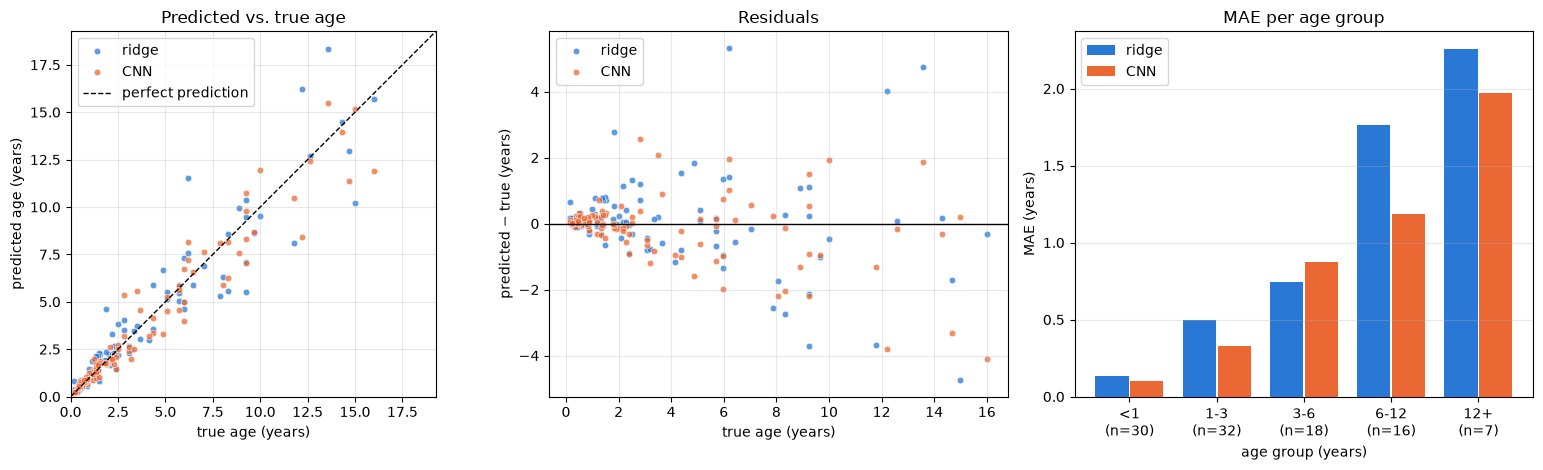

In [6]:
fig, (ax_pred, ax_res, ax_bar) = plt.subplots(1, 3, figsize=(16, 4.8))
top = max(age.max(), pred_cnn.max(), pred_ridge.max()) * 1.05

for name, pred in [("ridge", pred_ridge), ("CNN", pred_cnn)]:
    ax_pred.scatter(age, pred, s=22, alpha=0.75, color=COLOR[name], edgecolor="white", linewidth=0.5, label=name)
    ax_res.scatter(age, pred - age, s=22, alpha=0.75, color=COLOR[name], edgecolor="white", linewidth=0.5, label=name)
ax_pred.plot([0, top], [0, top], "k--", linewidth=1, label="perfect prediction")
ax_pred.set(xlim=(0, top), ylim=(0, top), aspect="equal",
            xlabel="true age (years)", ylabel="predicted age (years)", title="Predicted vs. true age")
ax_res.axhline(0, color="black", linewidth=1)
ax_res.set(xlabel="true age (years)", ylabel="predicted − true (years)", title="Residuals")

counts = pd.Series(group).value_counts().sort_index()
x = np.arange(len(GROUPS))
for k, name in enumerate(["ridge", "CNN"]):
    ax_bar.bar(x + (k - 0.5) * 0.4, table.loc[name, GROUPS], width=0.38, color=COLOR[name], label=name)
ax_bar.set_xticks(x, [f"{g}\n(n={counts[i]})" for i, g in enumerate(GROUPS)])
ax_bar.set(xlabel="age group (years)", ylabel="MAE (years)", title="MAE per age group")

for ax in (ax_pred, ax_res, ax_bar):
    ax.legend()
    ax.grid(alpha=0.3)
ax_bar.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG / "cnn_vs_ridge_val.png", dpi=150)
plt.show()
